# Домашнє завдання: Візуалізація даних з Matplotlib

## Опис завдання
У цьому домашньому завданні ви продовжите працювати з датасетом про оренду велосипедів `yulu_rental.csv`, але тепер будете використовувати бібліотеку Matplotlib для створення більш складних та налаштованих візуалізацій.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---


🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [7]:
# Завантаження даних
df = pd.read_csv('/content/drive/MyDrive/Python/Data/yulu_rental.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додаткові колонки
df['month'] = df.index.month
df['hour'] = df.index.hour
df['weekday'] = df.index.day_name()
df['weekday_num'] = df.index.weekday
df['week'] = df.index.isocalendar().week
df['year'] = df.index.year
df['day'] = df.index.day

## Завдання 1: Порівняння Pandas vs Matplotlib

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно впродовж всього періоду в даних двома способами:
1. Використовуючи Pandas (DataFrame.plot())
2. Використовуючи Matplotlib безпосередньо

В обох методах додайте маркери-кружечки. Можна також задати свій відмінний від стандартного колір.

Підказка: отримати потрібний формат даних найзручніше з методом датафрейму `resample`.

**Опишіть свої спостереження:** чим відрізняються 2 побудованих графіки? Який вам більше подобається?

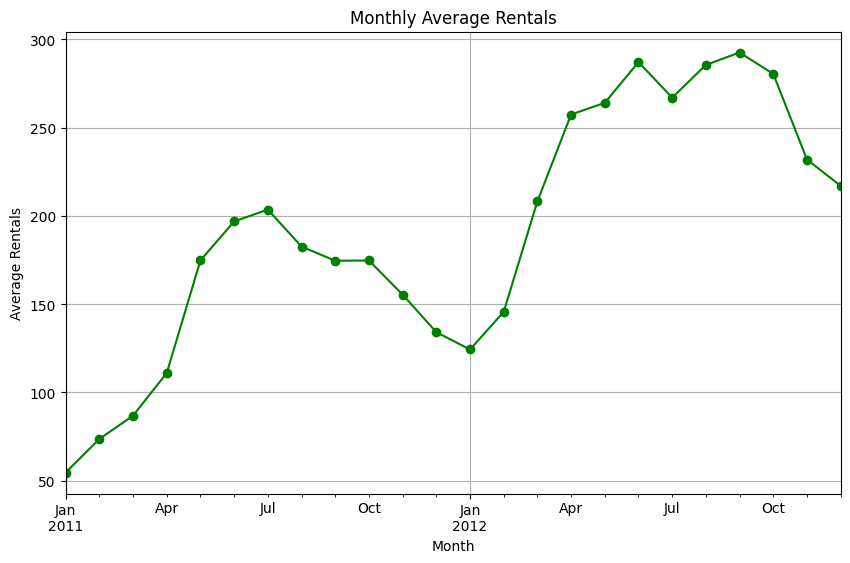

In [22]:
monthly_avg = df['count'].resample('ME').mean()
monthly_avg.plot(
    figsize=(10, 6),
    title='Monthly Average Rentals',
    marker='o',
    xlabel='Month',
    ylabel='Average Rentals',
    color='green',
    grid=True
);


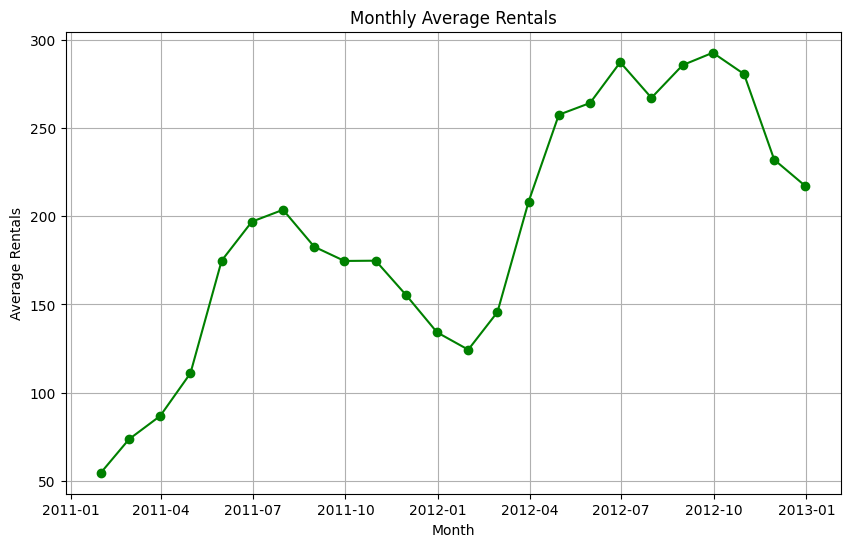

In [21]:
from matplotlib import colors
monthly_avg = df['count'].resample('ME').mean()
plt.figure(figsize=(10, 6))
plt.plot(monthly_avg, marker='o', linestyle='-',color='green')
plt.title('Monthly Average Rentals')
plt.xlabel('Month')
plt.ylabel('Average Rentals')
plt.grid(True)
plt.show()

**Спостереження:**
- Дані однакові, тому й лінія однакова: обидва графіки показують ту саму динаміку (зростання у 2012 році, пік улітку, спад узимку).
- **Pandas** — менше коду: все задається в одному `.plot()`. Підписи дат на осі X pandas форматує автоматично, місяці й роки виглядають акуратно.
- **Matplotlib** — більше коду (окремо `title`, `xlabel`, `grid`...), а дати на осі X показуються інакше. Зате кожен елемент графіка можна детально налаштувати.

**Що подобається більше:** для швидкого аналізу — Pandas, бо це просто й швидко.
Для складних графіків з тонким налаштуванням — Matplotlib.

## Завдання 2: Робота зі списками та numpy

**Завдання:**
Вам задані 3 списки:
1. Номер дня тижня.
2. Продажі в тиждень 1.
3. Продажі в тиждень 2.

Створіть графік, на якому лінійними графіками різних кольорів накладено продажі за обидва тижні.

Обовʼязково додайте назву графіку, підписи вісям ОХ, ОУ, назви кожного з рядів даних, легенду.

**Дайте відповіді на питання**
1. Судячи з графіку, в який тиждень проодажі були стабільніше?
2. Чи можете ви підкріпити свій висновок обчисленнями? Якими саме? Можна (але не обовʼязково) навести ці обчислення.

In [23]:
# Дані у вигляді списків
days = [1, 2, 3, 4, 5, 6, 7] # 1 - це понеділок
sales_week1 = [1349,1562,1600,1606,1510,959,822]  # Продажі за тиждень1
sales_week2 = [1321,1263,1162,1406,1421,1248,1204]  # Продажі за тиждень1

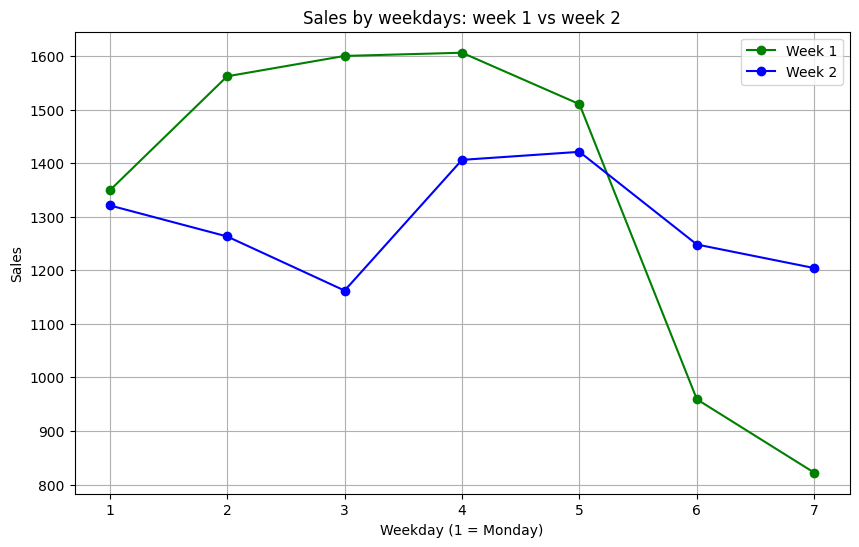

In [25]:
plt.figure(figsize=(10, 6))
plt.plot(days, sales_week1, marker='o', color='green', label='Week 1')
plt.plot(days, sales_week2, marker='o', color='blue', label='Week 2')

plt.title('Sales by weekdays: week 1 vs week 2')
plt.xlabel('Weekday (1 = Monday)')
plt.ylabel('Sales')
plt.xticks(days)
plt.grid(True)
plt.legend()
plt.show()

**Висновки:** у будні (пн–пт) продажі вищі в тижні 1, а у вихідні різко падають, тоді як тиждень 2 змінюється плавно - продажі стабільниіші.

In [29]:
for name, week in [('Week 1', sales_week1), ('Week 2', sales_week2)]:
    w = np.array(week)
    print(f'{name}: avg={w.mean():.0f}, std={w.std():.0f}, CV={w.std() / w.mean() * 100:.1f}%')

Week 1: avg=1344, std=300, CV=22.3%
Week 2: avg=1289, std=91, CV=7.1%


**Тиждень 1**: середнє 1344, std 300, CV = 22%: продажі зазвичай відхиляються на 22%.

**Тиждень 2**: середнє 1289, std 91, CV = 7%: відхилення лише 7%, тому цей тиждень стабільніший.

## Завдання 3: Subplot - 2x2 сітка графіків

**Завдання:**
Створіть сітку 2x2 з чотирма різними графіками, використовуючи `plt.subplot()`:
1. Лінійний графік середньої температури помісячно.
2. Стовпчикова діаграма середньої годинної кількості оренд за кварталами.
3. Гістограма вологості за всіма погодинними вимірами.
4. Scatter plot температури vs кількості оренд.

Кожен підграфік має містити всі необхідні підписи. Дашборд має містити назву.

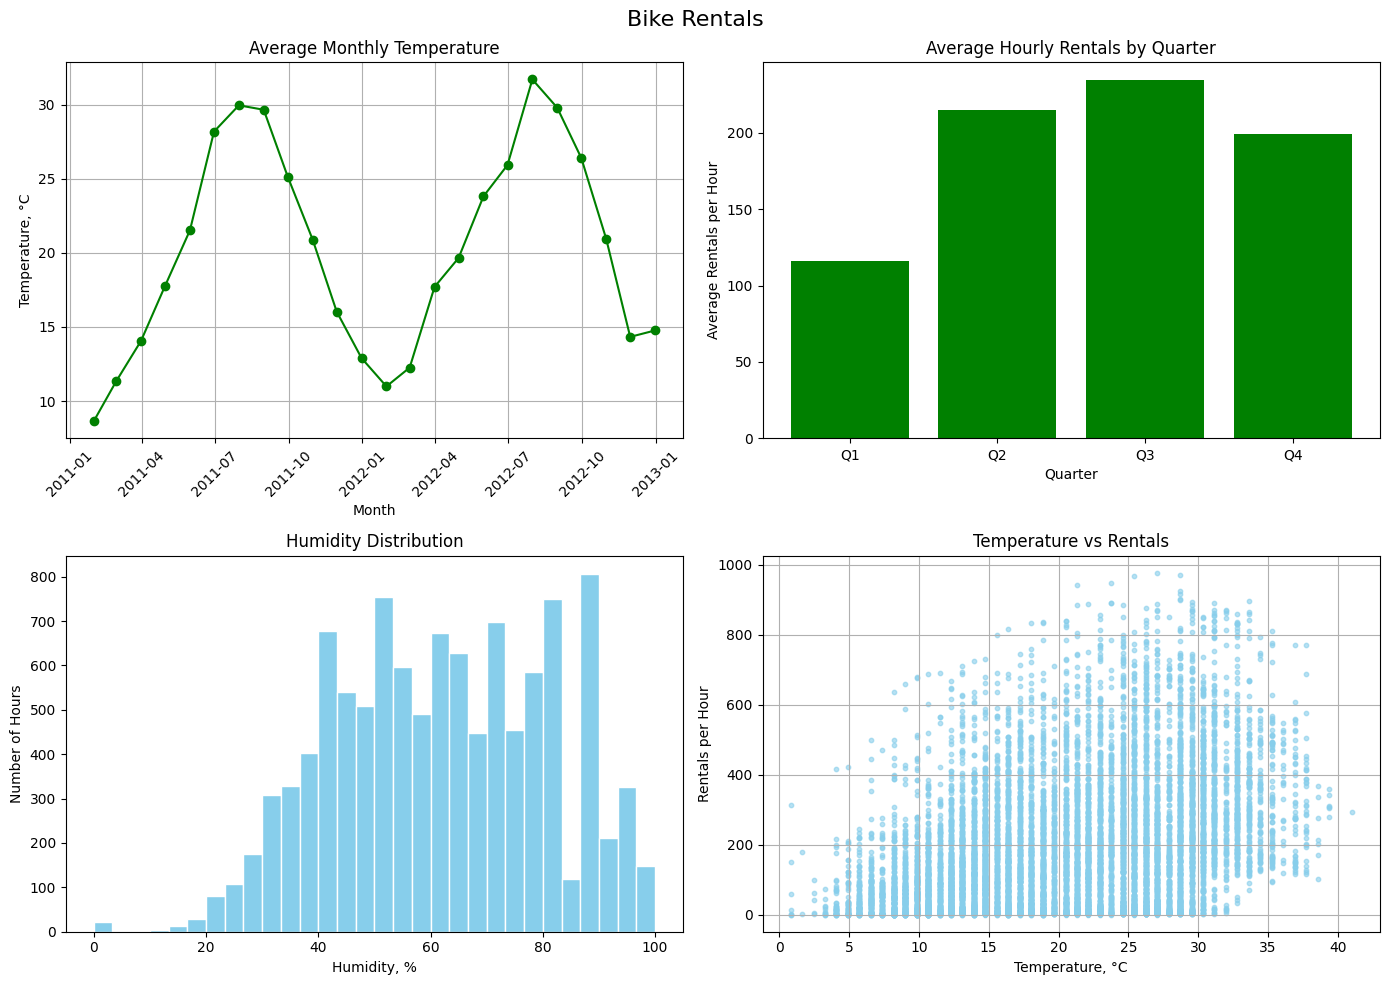

In [35]:
monthly_temp = df['temp'].resample('ME').mean()
quarter_avg = df.groupby('season')['count'].mean()
quarter_labels = ['Q1', 'Q2', 'Q3', 'Q4']

plt.figure(figsize=(14, 10))
plt.suptitle('Bike Rentals', fontsize=16)

# 1. Line plot
plt.subplot(2, 2, 1)
plt.plot(monthly_temp, marker='o', color='green')
plt.title('Average Monthly Temperature')
plt.xlabel('Month')
plt.ylabel('Temperature, °C')
plt.xticks(rotation=45)
plt.grid(True)

# 2. Bar chart
plt.subplot(2, 2, 2)
plt.bar(quarter_labels, quarter_avg, color='green')
plt.title('Average Hourly Rentals by Quarter')
plt.xlabel('Quarter')
plt.ylabel('Average Rentals per Hour')

# 3. Histogram
plt.subplot(2, 2, 3)
plt.hist(df['humidity'], bins=30, color='skyblue', edgecolor='white')
plt.title('Humidity Distribution')
plt.xlabel('Humidity, %')
plt.ylabel('Number of Hours')

# 4. Scatter plot
plt.subplot(2, 2, 4)
plt.scatter(df['temp'], df['count'], alpha=0.6, s=10, color='skyblue')
plt.title('Temperature vs Rentals')
plt.xlabel('Temperature, °C')
plt.ylabel('Rentals per Hour')
plt.grid(True)

plt.tight_layout()
plt.show()

## Завдання 4: Subplots - об'єктно-орієнтований підхід

**Завдання:**
Створіть той самий набір графіків, але використовуючи `fig, ax = plt.subplots()`.

**Дайте відповідь на питання своїми словами**
- Чим відрізняється підхід побудови кількох графіків на одній фігурі з `plt.subplots()` від `plt.subplot()`?

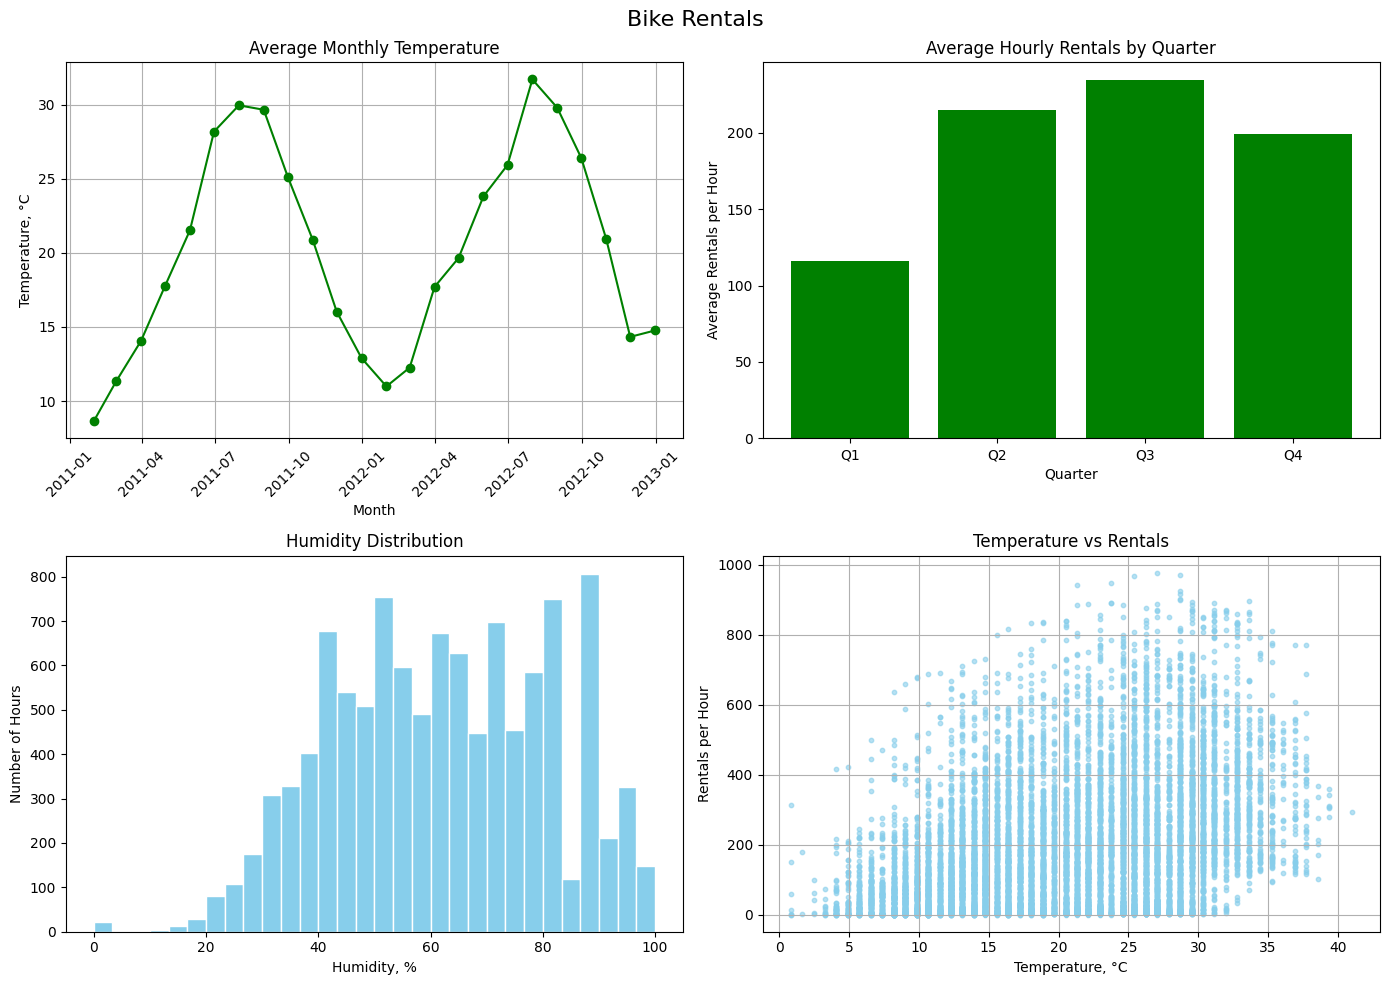

In [38]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Bike Rentals', fontsize=16)

# 1. Line plot
ax[0, 0].plot(monthly_temp, marker='o', color='green')
ax[0, 0].set_title('Average Monthly Temperature')
ax[0, 0].set_xlabel('Month')
ax[0, 0].set_ylabel('Temperature, °C')
ax[0, 0].tick_params(axis='x', rotation=45)
ax[0, 0].grid(True)

# 2. Bar chart
ax[0, 1].bar(quarter_labels, quarter_avg, color='green')
ax[0, 1].set_title('Average Hourly Rentals by Quarter')
ax[0, 1].set_xlabel('Quarter')
ax[0, 1].set_ylabel('Average Rentals per Hour')

# 3. Histogram
ax[1, 0].hist(df['humidity'], bins=30, color='skyblue', edgecolor='white')
ax[1, 0].set_title('Humidity Distribution')
ax[1, 0].set_xlabel('Humidity, %')
ax[1, 0].set_ylabel('Number of Hours')

# 4. Scatter plot
ax[1, 1].scatter(df['temp'], df['count'], alpha=0.6, s=10, color='skyblue')
ax[1, 1].set_title('Temperature vs Rentals')
ax[1, 1].set_xlabel('Temperature, °C')
ax[1, 1].set_ylabel('Rentals per Hour')
ax[1, 1].grid(True)

plt.tight_layout()
plt.show()

**Різниця між `plt.subplot()` і `plt.subplots()`:**
- `plt.subplot()` створює **один** графік за раз і робить його «активним». Усі наступні команди `plt.` застосовуються до нього, тому повернутися до попереднього незручно.
- `plt.subplots()` одразу створює **всю сітку** і повертає фігуру `fig` та графіки `ax`. Ми прямо вказуємо, який графік змінюємо (`ax[0, 1]`), тому можна працювати з ними в будь-якому порядку.

Для кількох графіків зручніший `plt.subplots()`: код зрозуміліший, і графіки можна налаштовувати в циклі.

## (Опціонально) Завдання 5: Тонкі налаштування форматування графіка

**Завдання:**
Подібно до прикладу, наведеного в лекції, створіть професійно оформлений графік помісячної динаміки оренди з максимальною кількістю деталей та налаштувань. Ваш графік має включати:

**Обов'язкові елементи:**
1. **Три лінії:** середнє, максимум, мінімум за місяцями
2. **Різні стилі ліній:** суцільна, пунктирна, крапкова + різні маркери
3. **Заливка області** між мінімумом та максимумом
4. **Дві анотації:** для найвищого та найнижчого середнього значення
5. **Горизонтальна лінія** середнього за весь рік
6. **Двошарова сітка:** основна та допоміжна
7. **Стилізована легенда** з тінню
8. **Текстовий блок** зі статистикою в кутку графіка
9. **Професійне оформлення:** заголовки, підписи осей з жирним шрифтом

**Результат:** Графік повинен виглядати як готова ілюстрація для бізнес-звіту або наукової публікації.

Приклад очікуваного результату.
![](https://drive.google.com/uc?id=1YoJByivzlqncEF2zbWu3EhGSZ7XRme8T)


**Питання для інтерпретації:**
1. Яка перевага додавання анотацій на графік?
2. Для чого використовується fill_between()?
3. Як текстовий блок допомагає в інтерпретації даних?